<a href="https://colab.research.google.com/github/USERNAME/Grokking-Deep-Learning/blob/main/03_making-predictions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 3: Forward Propagation
## Making a prediction with a neural network

**Companion notebook for *Grokking Deep Learning* (Andrew W. Trask, Manning)**

This notebook reproduces every code listing of Chapter 3 (pure Python first, then NumPy) and adds network diagrams drawn with Matplotlib so you can *see* what each listing computes. Run the cells from top to bottom.

---
## Step 1: Predict

Chapter 2 introduced the loop **predict → compare → learn**. This chapter is only about the first step. Turning inputs into a prediction is called **forward propagation**: numbers flow forward from the input, through the weights, to the output. (The numbers that change on every prediction are called *activations*; the weights stay put until learning updates them.)

**How much data per prediction?** Give the network as much information as a human would need to make the same call. One pixel is not enough to spot a cat, while the whole image is. In this chapter each prediction uses a handful of numbers about one baseball game.

Let's define a small helper that draws networks, so every architecture in this chapter can be visualised the same way.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def draw_net(sizes, weights=None, names=None, title=""):
    # sizes   : nodes per layer, e.g. [3, 1]
    # weights : list of arrays W[l][i][j] = weight from node i (layer l) to node j (layer l+1)
    # names   : list (per layer) of node labels
    fig, ax = plt.subplots(figsize=(1.9 * len(sizes) + 1.5, 0.9 * max(sizes) + 1.2))
    pos = [[(x, (n - 1) / 2 - j) for j in range(n)] for x, n in enumerate(sizes)]
    if weights is not None:
        for l, W in enumerate(weights):
            for i, (x0, y0) in enumerate(pos[l]):
                for j, (x1, y1) in enumerate(pos[l + 1]):
                    ax.plot([x0, x1], [y0, y1], color="#999", lw=1, zorder=1)
                    ax.text(x0 + .27 * (x1 - x0), y0 + .27 * (y1 - y0), f"{W[i][j]:g}",
                            fontsize=8, ha="center", va="center", zorder=3,
                            bbox=dict(fc="white", ec="none", pad=0.6))
    for l, layer in enumerate(pos):
        for j, (x, y) in enumerate(layer):
            ax.scatter([x], [y], s=900, color="#f7c873", ec="k", zorder=2)
            if names:
                ha = "right" if l == 0 else "left"
                dx = -.18 if l == 0 else .18
                if l in (0, len(sizes) - 1):
                    ax.text(x + dx, y, names[l][j], ha=ha, va="center", fontsize=9)
    ax.set_xlim(-1.4, len(sizes) - 1 + 1.4); ax.set_ylim(-max(sizes) / 2 - .4, max(sizes) / 2 + .4)
    ax.axis("off"); ax.set_title(title); plt.show()

---
## A simple neural network making a prediction

The smallest network possible has **one input, one weight, one output**. With a single data point per prediction (say, the team's average number of toes) and a single output (will they win?), one weight is all you need.

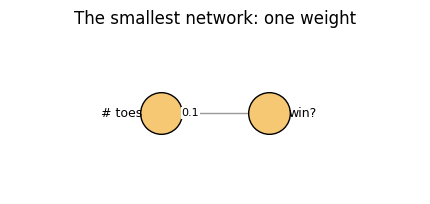

In [2]:
draw_net([1, 1], weights=[[[0.1]]], names=[["# toes"], ["win?"]], title="The smallest network: one weight")

---
## What is a neural network?

For now: **one or more weights that you multiply with the input data to produce a prediction.**

- *Input data* is a number you can easily measure (temperature, batting average, yesterday's price).
- A *prediction* is the network's guess about something harder to know.
- It is not always right. When it is wrong, learning (next chapter) will adjust the weight: lower it if the guess was too high, raise it if too low.

In [3]:
# The network
weight = 0.1

def neural_network(input, weight):
    prediction = input * weight
    return prediction

# Using the network to predict
number_of_toes = [8.5, 9.5, 10, 9]
input = number_of_toes[0]
pred = neural_network(input, weight)
print(pred)

0.8500000000000001


---
## What does this neural network do?

It **scales** the input. A weight of 2 doubles it; a weight of 0.01 divides it by 100. A helpful mental image is a **volume knob**: a large weight makes even a tiny input produce a loud prediction, a small weight keeps even big inputs quiet. Weights can also be negative.

The interface never changes, however large the network grows:

> **information (input)** + **knowledge (weights)** → **prediction**

Two more observations:
- The network has no memory. Feeding `number_of_toes[1]` next will not "remember" the previous prediction.
- A negative weight lets a network respond *inversely* (e.g. colder temperature → more coats worn).

In [4]:
# Playing with the knob
for w in [0.01, 0.1, 1, 2, -0.5]:
    print(f"weight = {w:>5}  ->  prediction = {neural_network(8.5, w):.3f}")

weight =  0.01  ->  prediction = 0.085
weight =   0.1  ->  prediction = 0.850
weight =     1  ->  prediction = 8.500
weight =     2  ->  prediction = 17.000
weight =  -0.5  ->  prediction = -4.250


---
## Making a prediction with multiple inputs

Is toes-per-player really enough to predict a win? Probably not, so let's give the network **three** facts per game: average toes, current win/loss record, and fan count (millions). Each input gets its *own* weight, and the three results are added up.

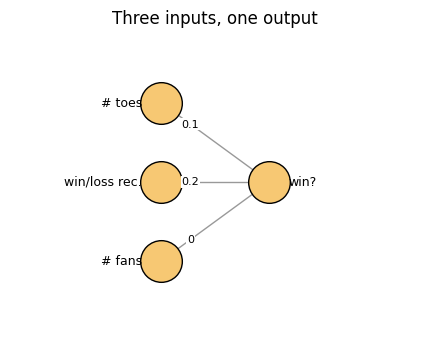

In [5]:
draw_net([3, 1], weights=[[[0.1], [0.2], [0.0]]],
         names=[["# toes", "win/loss rec.", "# fans"], ["win?"]],
         title="Three inputs, one output")

In [6]:
def w_sum(a, b):
    assert(len(a) == len(b))
    output = 0
    for i in range(len(a)):
        output += (a[i] * b[i])
    return output

weights = [0.1, 0.2, 0]

def neural_network(input, weights):
    pred = w_sum(input, weights)
    return pred

# Status at the beginning of the first four games of a season
toes  = [8.5, 9.5, 9.9, 9.0]     # average toes per player
wlrec = [0.65, 0.8, 0.8, 0.9]    # win fraction so far
nfans = [1.2, 1.3, 0.5, 1.0]     # fans (millions)

input = [toes[0], wlrec[0], nfans[0]]    # everything about game 0
pred = neural_network(input, weights)
print(pred)

0.9800000000000001


---
## Multiple inputs: what does this network do?

It performs a **weighted sum**: multiply each input by its weight, then add:

`8.5 × 0.1 + 0.65 × 0.2 + 1.2 × 0.0 = 0.85 + 0.13 + 0 = 0.98`

Two things to notice: `nfans` has zero influence (its weight is 0), and `toes` dominates because its input *times* weight is the largest. Impact always depends on **both** the input and the weight.

### Vocabulary
- **Vector**: a list of numbers (`input` and `weights` are vectors).
- **Elementwise operation**: pair up position 0 with 0, 1 with 1, ... and operate on each pair.
- **Dot product**: elementwise multiply, then sum. It is the weighted sum above.

**Challenge from the book: build the vector toolkit yourself.**

In [7]:
def elementwise_multiplication(vec_a, vec_b):
    assert(len(vec_a) == len(vec_b))
    return [vec_a[i] * vec_b[i] for i in range(len(vec_a))]

def elementwise_addition(vec_a, vec_b):
    assert(len(vec_a) == len(vec_b))
    return [vec_a[i] + vec_b[i] for i in range(len(vec_a))]

def vector_sum(vec_a):
    total = 0
    for x in vec_a:
        total += x
    return total

def vector_average(vec_a):
    return vector_sum(vec_a) / len(vec_a)

inp, w = [8.5, 0.65, 1.2], [0.1, 0.2, 0]
print("elementwise mult :", elementwise_multiplication(inp, w))
print("elementwise add  :", elementwise_addition(inp, w))
print("sum / average    :", vector_sum(inp), vector_average(inp))
print("dot product      :", vector_sum(elementwise_multiplication(inp, w)))   # same as w_sum

elementwise mult : [0.8500000000000001, 0.13, 0.0]
elementwise add  : [8.6, 0.8500000000000001, 1.2]
sum / average    : 10.35 3.4499999999999997
dot product      : 0.9800000000000001


The last line proves that a dot product is just *elementwise multiplication followed by a sum*, so it equals `w_sum` from above (≈ 0.98).

---
## The intuition behind the dot product

A dot product measures **how much two vectors overlap** (their similarity).

- Identical vectors give a big score; vectors with no overlapping non-zero positions score 0.
- It behaves like a **logical AND**: a position contributes only if *both* vectors have value there. Summing across positions adds an **OR** flavour.
- Partial values give a partial AND (useful for probabilities).
- A **negative** weight acts like a **NOT**: it pulls the score down.

In [8]:
a = [ 0, 1, 0, 1]
b = [ 1, 0, 1, 0]
c = [ 0, 1, 1, 0]
d = [.5, 0,.5, 0]
e = [ 0, 1,-1, 0]

print("w_sum(a,b) =", w_sum(a, b), " (no shared position -> 0)")
print("w_sum(b,c) =", w_sum(b, c), " (one shared position -> 1)")
print("w_sum(b,d) =", w_sum(b, d), " (shared, but d is only 0.5 -> partial AND)")
print("w_sum(c,c) =", w_sum(c, c), " (identical -> highest)")
print("w_sum(c,e) =", w_sum(c, e), " (negative weight cancels the overlap)")
print("w_sum(e,e) =", w_sum(e, e), " (negative x negative = positive)")

w_sum(a,b) = 0  (no shared position -> 0)
w_sum(b,c) = 1  (one shared position -> 1)
w_sum(b,d) = 1.0  (shared, but d is only 0.5 -> partial AND)
w_sum(c,c) = 2  (identical -> highest)
w_sum(c,e) = 0  (negative weight cancels the overlap)
w_sum(e,e) = 2  (negative x negative = positive)


---
## A crude language for reading weights

Imagine each `weights` vector as a rule that asks "does the input look like me?". The book offers this informal translation (the result is a high score):

| weights | reads as |
|---|---|
| `[1, 0, 1]` | input[0] **OR** input[2] |
| `[0, 0, 1]` | input[2] |
| `[1, 0, -1]` | input[0] **OR NOT** input[2] |
| `[-1, 0, -1]` | **NOT** input[0] **OR NOT** input[2] |
| `[0.5, 0, 1]` | a **BIG** input[0] or input[2] |

It's rough, but it helps picture what a trained weight vector is "looking for". Remember too: **weights cannot be shuffled**. Each one is tied to a specific input position.

---
## Multiple inputs: complete runnable code (NumPy version)

NumPy provides vectors and a fast `dot`, so the helper `w_sum` is no longer needed. The book writes everything manually first so that `dot` isn't magic.

In [9]:
import numpy as np

weights = np.array([0.1, 0.2, 0])

def neural_network(input, weights):
    pred = input.dot(weights)
    return pred

toes  = np.array([8.5, 9.5, 9.9, 9.0])
wlrec = np.array([0.65, 0.8, 0.8, 0.9])
nfans = np.array([1.2, 1.3, 0.5, 1.0])

input = np.array([toes[0], wlrec[0], nfans[0]])
pred = neural_network(input, weights)
print(pred)

0.9800000000000001


---
## Making a prediction with multiple outputs

One input, several predictions. Each output is its **own independent mini-network** that happens to share the same input, which makes this the easiest extension. Here the current win/loss record predicts three things: *hurt?*, *win?* and *sad?*.

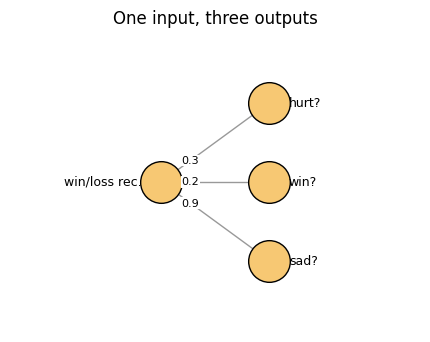

In [10]:
draw_net([1, 3], weights=[[[0.3, 0.2, 0.9]]],
         names=[["win/loss rec."], ["hurt?", "win?", "sad?"]],
         title="One input, three outputs")

In [11]:
def ele_mul(number, vector):
    output = [0, 0, 0]
    assert(len(output) == len(vector))
    for i in range(len(vector)):
        output[i] = number * vector[i]
    return output

weights = [0.3, 0.2, 0.9]

def neural_network(input, weights):
    pred = ele_mul(input, weights)
    return pred

wlrec = [0.65, 0.8, 0.8, 0.9]
input = wlrec[0]
pred = neural_network(input, weights)
print(pred)

[0.195, 0.13, 0.5850000000000001]


---
## Predicting with multiple inputs and outputs

Combine both: every input connects to every output with its own weight (3 × 3 = 9 weights here).

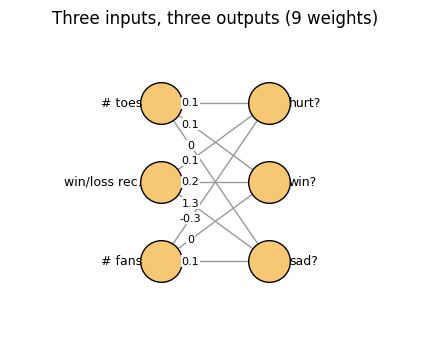

In [12]:
W_book = [[0.1, 0.1, -0.3],     # hurt?  (row = one output node)
          [0.1, 0.2,  0.0],     # win?
          [0.0, 1.3,  0.1]]     # sad?
draw_net([3, 3], weights=[np.array(W_book).T],
         names=[["# toes", "win/loss rec.", "# fans"], ["hurt?", "win?", "sad?"]],
         title="Three inputs, three outputs (9 weights)")

In [13]:
#         toes  %win  #fans
weights = [[0.1, 0.1, -0.3],   # hurt?
           [0.1, 0.2,  0.0],   # win?
           [0.0, 1.3,  0.1]]   # sad?

def w_sum(a, b):
    assert(len(a) == len(b))
    output = 0
    for i in range(len(a)):
        output += (a[i] * b[i])
    return output

def vect_mat_mul(vect, matrix):
    assert(len(vect) == len(matrix[0]))
    output = [0] * len(matrix)
    for i in range(len(matrix)):
        output[i] = w_sum(vect, matrix[i])
    return output

def neural_network(input, weights):
    pred = vect_mat_mul(input, weights)
    return pred

toes  = [8.5, 9.5, 9.9, 9.0]
wlrec = [0.65, 0.8, 0.8, 0.9]
nfans = [1.2, 1.3, 0.5, 1.0]

input = [toes[0], wlrec[0], nfans[0]]
pred = neural_network(input, weights)
print(pred)

[0.555, 0.9800000000000001, 0.9650000000000001]


---
## Multiple inputs and outputs: how does it work?

Think of it as **three independent dot products**, one per output node, each using the whole input vector:

- hurt = 8.5·0.1 + 0.65·0.1 + 1.2·(−0.3) = **0.555**
- win = 8.5·0.1 + 0.65·0.2 + 1.2·0.0 = **0.98**
- sad = 8.5·0.0 + 0.65·1.3 + 1.2·0.1 = **0.965**

`weights` here is a list of vectors, which is a **matrix**. Running one dot product per row is **vector–matrix multiplication**, implemented above in `vect_mat_mul`. (Formal linear algebra stores weights as columns instead of rows; that is why the NumPy version later uses `.T`.)

---
## Predicting on predictions (stacked networks)

The output of one layer can be the *input* of another. The middle layer is called a **hidden layer** because you never see its values in the final answer. This gives two vector–matrix multiplications in a row. Some datasets (images, for instance) hold patterns too complex for a single weight matrix, which is the motivation for stacking (explored in later chapters).

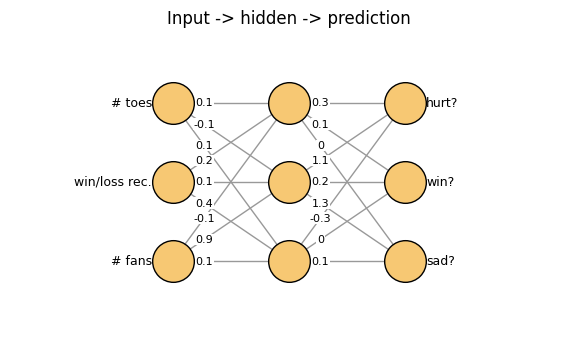

In [14]:
ih = [[0.1, 0.2, -0.1],    # hid[0]
      [-0.1, 0.1, 0.9],    # hid[1]
      [0.1, 0.4,  0.1]]    # hid[2]
hp = [[0.3, 1.1, -0.3],    # hurt?
      [0.1, 0.2,  0.0],    # win?
      [0.0, 1.3,  0.1]]    # sad?
draw_net([3, 3, 3], weights=[np.array(ih).T, np.array(hp).T],
         names=[["# toes", "win/loss rec.", "# fans"], None, ["hurt?", "win?", "sad?"]],
         title="Input -> hidden -> prediction")

In [15]:
# Pure Python
ih_wgt = [[0.1, 0.2, -0.1],   # hid[0]
          [-0.1, 0.1, 0.9],   # hid[1]
          [0.1, 0.4, 0.1]]    # hid[2]

hp_wgt = [[0.3, 1.1, -0.3],   # hurt?
          [0.1, 0.2, 0.0],    # win?
          [0.0, 1.3, 0.1]]    # sad?

weights = [ih_wgt, hp_wgt]

def neural_network(input, weights):
    hid  = vect_mat_mul(input, weights[0])
    pred = vect_mat_mul(hid,   weights[1])
    return pred

input = [toes[0], wlrec[0], nfans[0]]
print(neural_network(input, weights))

[0.21350000000000002, 0.14500000000000002, 0.5065]


In [16]:
# NumPy version
ih_wgt = np.array([[0.1, 0.2, -0.1],
                   [-0.1, 0.1, 0.9],
                   [0.1, 0.4, 0.1]]).T

hp_wgt = np.array([[0.3, 1.1, -0.3],
                   [0.1, 0.2, 0.0],
                   [0.0, 1.3, 0.1]]).T

weights = [ih_wgt, hp_wgt]

def neural_network(input, weights):
    hid  = input.dot(weights[0])
    pred = hid.dot(weights[1])
    return pred

toes  = np.array([8.5, 9.5, 9.9, 9.0])
wlrec = np.array([0.65, 0.8, 0.8, 0.9])
nfans = np.array([1.2, 1.3, 0.5, 1.0])

input = np.array([toes[0], wlrec[0], nfans[0]])
print("hidden layer:", input.dot(ih_wgt))
print("prediction  :", neural_network(input, weights))

hidden layer: [0.86  0.295 1.23 ]
prediction  : [0.2135 0.145  0.5065]


Both versions give ≈ `[0.2135, 0.145, 0.5065]` (the book's figure rounds these to .214, .145, .507). The `.T` flips rows and columns so that `input.dot(W)` treats each *column* as one output node, matching the row-based layout used by the pure-Python version.

---
## A quick primer on NumPy

Two skills matter: creating vectors/matrices and **tracking shapes**.

In [17]:
a = np.array([0, 1, 2, 3])            # a vector
b = np.array([4, 5, 6, 7])            # another vector
c = np.array([[0, 1, 2, 3],
              [4, 5, 6, 7]])          # a 2 x 4 matrix
d = np.zeros((2, 4))                  # 2 x 4 matrix of zeros
e = np.random.rand(2, 5)              # 2 x 5 matrix of random numbers in [0, 1)

for name, arr in [("a", a), ("b", b), ("c", c), ("d", d), ("e", e)]:
    print(name, arr.shape)
    print(arr)

a (4,)
[0 1 2 3]
b (4,)
[4 5 6 7]
c (2, 4)
[[0 1 2 3]
 [4 5 6 7]]
d (2, 4)
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]]
e (2, 5)
[[0.10188783 0.94317257 0.21301946 0.2521115  0.9135675 ]
 [0.6334069  0.85915368 0.21642748 0.80646236 0.5915608 ]]


### NumPy decides the operation from the shapes
For `+ - * /`: shapes must match in their column count, or one operand must be a single number (a scalar).

In [18]:
print(a * 0.1)       # vector x scalar
print(c * 0.2)       # matrix x scalar
print(a * b)         # elementwise, positions paired
print(a * b * 0.2)   # elementwise, then scale
print(a * c)         # `a` is multiplied into EACH ROW of c (same number of columns)

try:
    print(a * e)     # 4 columns vs 5 columns
except ValueError as err:
    print("ValueError:", err)

[0.  0.1 0.2 0.3]
[[0.  0.2 0.4 0.6]
 [0.8 1.  1.2 1.4]]
[ 0  5 12 21]
[0.  1.  2.4 4.2]
[[ 0  1  4  9]
 [ 0  5 12 21]]
ValueError: operands could not be broadcast together with shapes (4,) (2,5) 


### The golden rule of `dot`
Write the shapes side by side; the **inner numbers must match**, and the outer ones are the result: `(a, b) · (b, c) → (a, c)`.

In [19]:
print(np.zeros((1, 4)).dot(np.zeros((4, 3))).shape)       # (1, 3)
print(np.zeros((2, 4)).dot(np.zeros((4, 3))).shape)       # (2, 3)
print(np.zeros((2, 1)).dot(np.zeros((1, 3))).shape)       # (2, 3)
print(np.zeros((5, 4)).T.dot(np.zeros((5, 6))).shape)     # (4, 6): .T turned (5,4) into (4,5)

try:
    np.zeros((5, 4)).dot(np.zeros((5, 6)))                # (5,4)·(5,6): 4 != 5
except ValueError as err:
    print("ValueError:", err)

(1, 3)
(2, 3)
(2, 3)
(4, 6)
ValueError: shapes (5,4) and (5,6) not aligned: 4 (dim 1) != 5 (dim 0)


---
## Summary

- A neural network predicts through **repeated weighted sums** (dot products) of its input.
- Learning to set good **weight values** is what gives a network its intelligence; this chapter only used values handed to us.
- Larger networks reuse the same few rules: more inputs → longer vectors, more outputs → weight **matrices**, more layers → **stacking**.
- Everything here is **forward propagation**. Next up: *how do we find good weights?*